# The Problem
    
    Open Data BCN, a project that was born in 2010, implementing the portal in 2011, has evolved and is now part of the Barcelona Ciutat Digital strategy, fostering a pluralistic digital economy and developing a new model of urban innovation based on the transformation and digital innovation of the public sector and the implication among companies, administrations, the academic world, organizations, communities and people, with a clear public and citizen leadership.
    
Learn more about it here:<br>
<a href=https://opendata-ajuntament.barcelona.cat/en/open-data-bcn>OpenDataBCN</a> 

    In this datatale we are interested in analyzing the data and predicting serious injuries suffered in each accident.

    Based on our problem statement what are X and Y in the dataset?

    Serious injuries is our target(Y)
    We can't for sure say all other features become our X because we don't know yet what our analysis might uncover and how many feilds we would end up using in model building

### Importing Dependencies

In [103]:
import numpy as np
import pandas as pd

import reverse_geocoder as rg
import pprint
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import style
from sklearn import metrics

from sklearn.preprocessing import MinMaxScaler 
from scipy.stats import chi2_contingency
from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier


In [2]:
#Reading Data
barcelona=pd.read_csv(r"barcelona-data-sets\accidents_2017.csv")
barcelona.head()

,Id,District Name,Neighborhood Name,Street,Weekday,Month,Day,Hour,Part of the day,Mild injuries,Serious injuries,Victims,Vehicles involved,Longitude,Latitude
0,2017S008429,Unknown,Unknown,Número 27 ...,Friday,October,13,8,Morning,2,0,2,2,2.125624,41.340045
1,2017S007316,Unknown,Unknown,Número 3 Zona Franca / Número 50 Zona Franca ...,Friday,September,1,13,Morning,2,0,2,2,2.120452,41.339426
2,2017S010210,Unknown,Unknown,Litoral (Besòs) ...,Friday,December,8,21,Afternoon,5,0,5,2,2.167356,41.360885
3,2017S006364,Unknown,Unknown,Número 3 Zona Franca ...,Friday,July,21,2,Night,1,0,1,2,2.124529,41.337668
4,2017S004615,Sant Martí,el Camp de l'Arpa del Clot,Las Navas de Tolosa ...,Thursday,May,25,14,Afternoon,1,0,1,3,2.185272,41.416365


    Why did we use a leading 'r' in the read_csv function?

    Without this r, python would have considered \a from \accidents_2017.csv as a regex operator. To specify that the following text is not a regex operator but raw text we define leading 'r'

In [3]:
barcelona.describe()

,Day,Hour,Mild injuries,Serious injuries,Victims,Vehicles involved,Longitude,Latitude
count,10339.000000,10339.000000,10339.000000,10339.000000,10339.000000,10339.000000,10339.000000,10339.000000
mean,15.775994,13.811394,1.154174,0.023310,1.178644,1.920979,2.162832,41.399346
std,8.763455,5.316490,0.742294,0.163803,0.735145,0.714011,0.024176,0.021251
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.091855,41.323094
25%,8.000000,10.000000,1.000000,0.000000,1.000000,2.000000,2.144985,41.386288
50%,16.000000,14.000000,1.000000,0.000000,1.000000,2.000000,2.163399,41.396730
75%,23.000000,18.000000,1.000000,0.000000,1.000000,2.000000,2.180179,41.411038
max,31.000000,23.000000,10.000000,4.000000,10.000000,14.000000,2.222572,41.468244


In [4]:
barcelona.describe(include='object')

,Id,District Name,Neighborhood Name,Street,Weekday,Month,Part of the day
count,10339,10339,10339,10339,10339,10339,10339
unique,10335,11,74,4253,7,12,3
top,2017S003286,Eixample,la Dreta de l'Eixample,Corts Catalanes ...,Friday,November,Afternoon
freq,2,3029,1167,219,1761,991,5082


In [5]:
barcelona.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10339 entries, 0 to 10338
Data columns (total 15 columns):
Id                   10339 non-null object
District Name        10339 non-null object
Neighborhood Name    10339 non-null object
Street               10339 non-null object
Weekday              10339 non-null object
Month                10339 non-null object
Day                  10339 non-null int64
Hour                 10339 non-null int64
Part of the day      10339 non-null object
Mild injuries        10339 non-null int64
Serious injuries     10339 non-null int64
Victims              10339 non-null int64
Vehicles involved    10339 non-null int64
Longitude            10339 non-null float64
Latitude             10339 non-null float64
dtypes: float64(2), int64(6), object(7)
memory usage: 1.2+ MB


    Findings from Describe and info:
    
    - On an average there are about 1.15 mild injuries and 0.02 serious injuries each day
    - There are a maximum of 10 mild injuries and 4 serious ones on a given day
    - It doesn't look like an injury directly translates to a person i.e, if there's 1 injury doesn't necessarily mean there's only one person involved in the accident instead it means that only one person got injured
    - The mean number of vehicles involved in all the accidents is 1.9 this means, not all accidents are because of a collision with another vehicle but sometimes someone might have just fallen off a 2 wheeler or a car crashed into a pole or tree
    - It doesn't make any sense to check descriptive statistics for latitude and longitude unless we are creative. The mean lat and long values are very close to the first entry and hence we can say the districts around first record could be accident prone zones
    - There aren't any null values in the data, that saves us a step in preprocessing

### Preprocessing and EDA

    We can see many districts without names, how can we address this?

    We can use the lat and longitudes to identify the district. We use reverse_geocoder package for this purpose

In [8]:
def reverseGeocode(coordinates):
    result = rg.search(coordinates)
    return result
coordinates =(2.125, 41.340)
a=reverseGeocode(coordinates)
a

[OrderedDict([('lat', '2.34464'),
              ('lon', '42.27644'),
              ('name', 'Baardheere'),
              ('admin1', 'Gedo'),
              ('admin2', ''),
              ('cc', 'SO')])]

In [9]:
#let's extract the district name from above dictionary
a[0]['name']

'Baardheere'

    We shall now repeat the same process for all the rows with unknown districts, We shall implement this with a for loop but do you think there's a better way?

    It's preferred not to use a for loop unless there's no other option. We are using 'for' here to encourage you to implement the same with an apply statement. 
    You can take this hint:
    barcelona['District Name'] = barcelona['District Name'].apply(function_to_impute_district_name)
    Now all you need to do is write the logic in 'function_to_impute_district_name'

In [10]:
for i in range(barcelona.shape[0]):
    if barcelona['District Name'][i] == 'Unknown':
        code= reverseGeocode((barcelona.Longitude[i], barcelona.Latitude[i]))
        barcelona['District Name'][i]= code[0]['name']
barcelona.head()

C:\Users\manik\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  after removing the cwd from sys.path.


,Id,District Name,Neighborhood Name,Street,Weekday,Month,Day,Hour,Part of the day,Mild injuries,Serious injuries,Victims,Vehicles involved,Longitude,Latitude
0,2017S008429,Baardheere,Unknown,Número 27 ...,Friday,October,13,8,Morning,2,0,2,2,2.125624,41.340045
1,2017S007316,Baardheere,Unknown,Número 3 Zona Franca / Número 50 Zona Franca ...,Friday,September,1,13,Morning,2,0,2,2,2.120452,41.339426
2,2017S010210,Baardheere,Unknown,Litoral (Besòs) ...,Friday,December,8,21,Afternoon,5,0,5,2,2.167356,41.360885
3,2017S006364,Baardheere,Unknown,Número 3 Zona Franca ...,Friday,July,21,2,Night,1,0,1,2,2.124529,41.337668
4,2017S004615,Sant Martí,el Camp de l'Arpa del Clot,Las Navas de Tolosa ...,Thursday,May,25,14,Afternoon,1,0,1,3,2.185272,41.416365


    Part of the day correction
    Hour of day not matching with part of the day...(13 ie 1pm is showed as Morning, 21 ie 9PM is shown as Afternoon)


In [12]:
def get_part_of_day(hour):
    return (
        "morning" if 5 <= hour <= 11
        else
        "afternoon" if 12 <= hour <= 17
        else
        "evening" if 18 <= hour <= 22
        else
        "night"
    )
for i in range(0, 24):
    print('hour {0} is {1}'.format(i, get_part_of_day(i)))

hour 0 is night
hour 1 is night
hour 2 is night
hour 3 is night
hour 4 is night
hour 5 is morning
hour 6 is morning
hour 7 is morning
hour 8 is morning
hour 9 is morning
hour 10 is morning
hour 11 is morning
hour 12 is afternoon
hour 13 is afternoon
hour 14 is afternoon
hour 15 is afternoon
hour 16 is afternoon
hour 17 is afternoon
hour 18 is evening
hour 19 is evening
hour 20 is evening
hour 21 is evening
hour 22 is evening
hour 23 is night


In [13]:
for i in range(barcelona.shape[0]):
    code= get_part_of_day((barcelona.Hour[i]))
    barcelona['Part of the day'][i]= code

C:\Users\manik\Anaconda3\lib\site-packages\ipykernel_launcher.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  This is separate from the ipykernel package so we can avoid doing imports until


In [14]:
barcelona.head()

,Id,District Name,Neighborhood Name,Street,Weekday,Month,Day,Hour,Part of the day,Mild injuries,Serious injuries,Victims,Vehicles involved,Longitude,Latitude
0,2017S008429,Baardheere,Unknown,Número 27 ...,Friday,October,13,8,morning,2,0,2,2,2.125624,41.340045
1,2017S007316,Baardheere,Unknown,Número 3 Zona Franca / Número 50 Zona Franca ...,Friday,September,1,13,afternoon,2,0,2,2,2.120452,41.339426
2,2017S010210,Baardheere,Unknown,Litoral (Besòs) ...,Friday,December,8,21,evening,5,0,5,2,2.167356,41.360885
3,2017S006364,Baardheere,Unknown,Número 3 Zona Franca ...,Friday,July,21,2,night,1,0,1,2,2.124529,41.337668
4,2017S004615,Sant Martí,el Camp de l'Arpa del Clot,Las Navas de Tolosa ...,Thursday,May,25,14,afternoon,1,0,1,3,2.185272,41.416365


#####    Top Districts prone to Accidents 

In [16]:
x = barcelona['District Name'].value_counts().index
print(x)

Index(['Eixample', 'Sant Martí', 'Sants-Montjuïc', 'Sarrià-Sant Gervasi',
       'Horta-Guinardó', 'Les Corts', 'Ciutat Vella', 'Sant Andreu',
       'Nou Barris', 'Gràcia', 'Baardheere'],
      dtype='object')


In [17]:
y = barcelona['District Name'].value_counts()
print(y)

Eixample               3029
Sant Martí             1336
Sants-Montjuïc         1104
Sarrià-Sant Gervasi    1104
Horta-Guinardó          743
Les Corts               726
Ciutat Vella            600
Sant Andreu             597
Nou Barris              542
Gràcia                  531
Baardheere               27
Name: District Name, dtype: int64


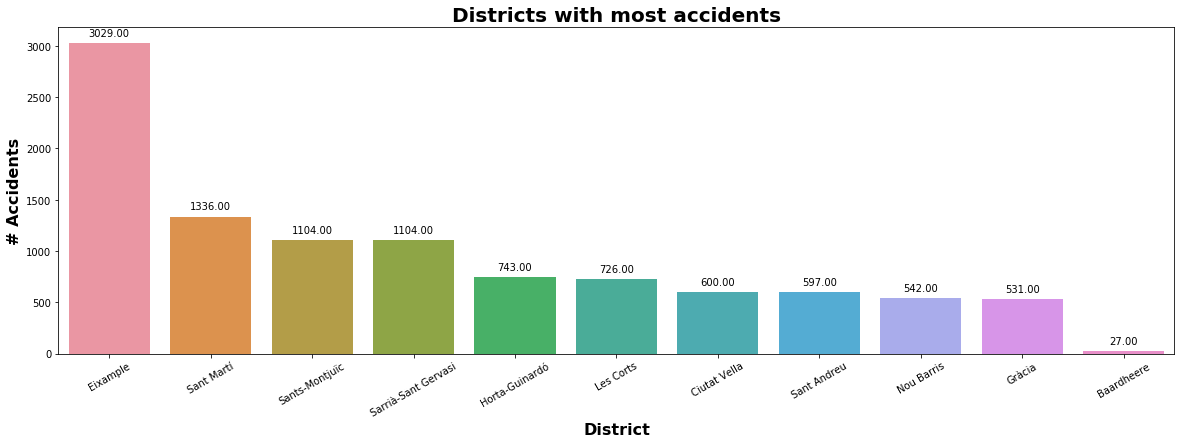

In [18]:
plt.figure(figsize=(20,6))
x = barcelona['District Name'].value_counts().index
y = barcelona['District Name'].value_counts()
ax = sns.barplot(x=x, y=y)
plt.title("Districts with most accidents", fontsize=20).set_weight('bold')
#value_barplot_label(ax)
plt.ylabel('# Accidents', fontsize=16).set_weight('bold')
plt.xlabel('District', fontsize=16).set_weight('bold')
plt.xticks(rotation=30)

for p in ax.patches:
    ax.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()), ha = 'center', va = 'center', 
               xytext = (0, 10), textcoords = 'offset points')
#tick_format(ax,1)

    We can see that Eiample has more no of accidents and Baardheere has less Accidents 

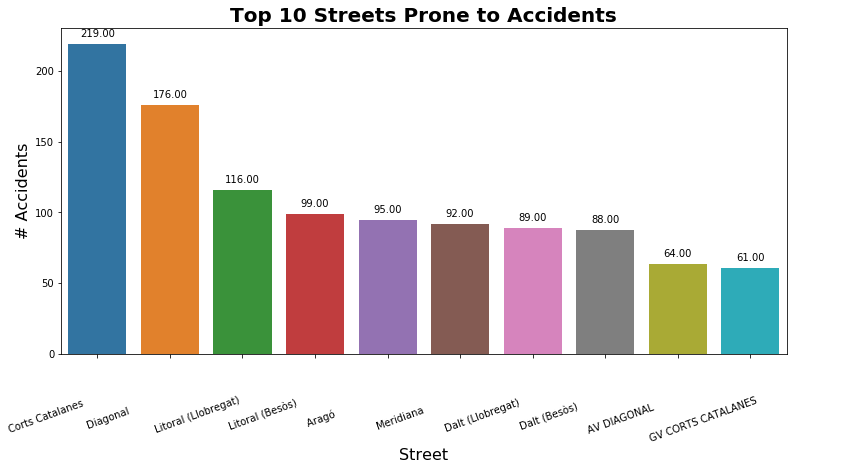

In [14]:
plt.figure(figsize=(13,6))
x = barcelona['Street'].value_counts().index[:10]
y = barcelona['Street'].value_counts()[:10]
splot = sns.barplot(x=x, y=y)
plt.title("Top 10 Streets Prone to Accidents", fontsize=20).set_weight('bold')
#value_barplot_label(ax)
plt.ylabel('# Accidents', fontsize=16)
plt.xlabel('Street', fontsize=16)
plt.xticks(rotation=20)

for p in splot.patches:
    splot.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()), ha = 'center', va = 'center', 
               xytext = (0, 10), textcoords = 'offset points')
#tick_format(ax,1)

    Corts Catalenes Street is prone to more no of Accidents

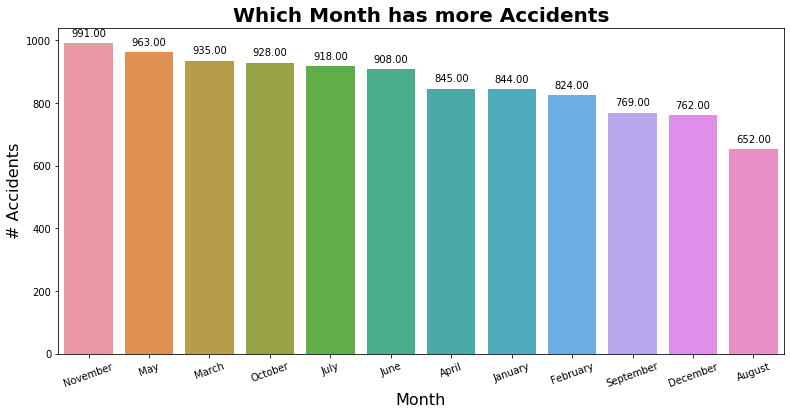

In [20]:
#Which month is having more no of accidents 
plt.figure(figsize=(13,6))
x = barcelona['Month'].value_counts().index
y = barcelona['Month'].value_counts()
splot = sns.barplot(x=x, y=y)
plt.title("Which Month has more Accidents", fontsize=20).set_weight('bold')
#value_barplot_label(ax)
plt.ylabel('# Accidents', fontsize=16)
plt.xlabel('Month', fontsize=16)
plt.xticks(rotation=20)

for p in splot.patches:
    splot.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()), ha = 'center', va = 'center', 
               xytext = (0, 10), textcoords = 'offset points')
#tick_format(ax,1)



    August has least number of accidents while november has most, could we say this is because of the thanksgiving rush? It sure is possible but we don't have enough proof to support our statement

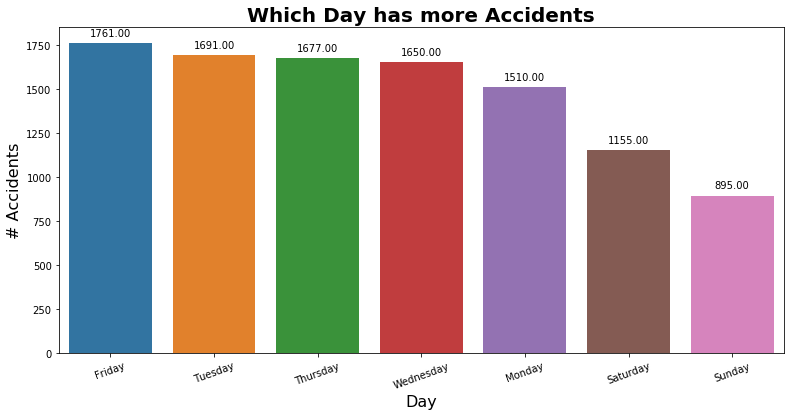

In [21]:
#Which day is having more no of accidents 


plt.figure(figsize=(13,6))
x = barcelona['Weekday'].value_counts().index
y = barcelona['Weekday'].value_counts()
splot = sns.barplot(x=x, y=y)
plt.title("Which Day has more Accidents", fontsize=20).set_weight('bold')
#value_barplot_label(ax)
plt.ylabel('# Accidents', fontsize=16)
plt.xlabel('Day', fontsize=16)
plt.xticks(rotation=20)

for p in splot.patches:
    splot.annotate(format(p.get_height(), '.2f'), (p.get_x() + p.get_width() / 2., p.get_height()), ha = 'center', va = 'center', 
               xytext = (0, 10), textcoords = 'offset points')
#tick_format(ax,1)

    People probably tend to stay home on a sunday

In [22]:
#Weekday and Hour of day

cross_tab = pd.crosstab(barcelona['Weekday'], barcelona['Part of the day']).apply(lambda x: x/x.sum() * 100, axis = 1).round(2)



In [23]:
sorter = ['Sunday','Monday', 'Tuesday','Wednesday','Thursday','Friday','Saturday']
sorterIndex = dict(zip(sorter, range(len(sorter))))

cross_tab['id'] = cross_tab.index
cross_tab['id'] = cross_tab['id'].map(sorterIndex)
cross_tab.sort_values('id',inplace=True)
cross_tab.head()


Part of the day,afternoon,evening,morning,night,id
Weekday,,,,,
Sunday,34.19,28.04,22.01,15.75,0
Monday,39.21,25.36,30.00,5.43,1
Tuesday,39.50,24.96,30.69,4.85,2
Wednesday,38.36,27.33,29.76,4.55,3
Thursday,39.00,27.31,28.26,5.43,4


<Figure size 1440x720 with 0 Axes>

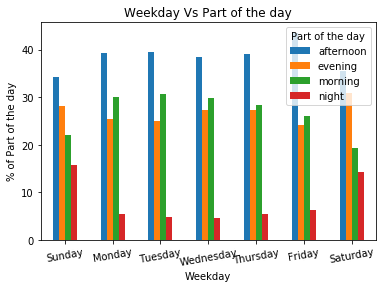

In [26]:
acc=cross_tab.drop(['id'],axis=1)
acc.plot.bar()


plt.xlabel('{}'.format('Weekday'))
plt.ylabel('% of {}'.format('Part of the day'))
plt.title('{} Vs {}'.format('Weekday','Part of the day'))
plt.xticks(rotation=10)
plt.show()



    There are more no of accidents in Afternoon especially Friday Afternoon
    Less no of accidents in the night compared to evening and afternoon
    Saturday and Sunday morning have less no of accidents  compared to weekdays, this might be because of holidays 
    Saturday and Sunday evenings, nights have more no of accidents  compared to weekdays, this might be because of weekend journeys 


In [27]:
#Grouping by Mild Injuries and Serious Injuries
import numpy as np
import pandas as pd
injuries = barcelona.groupby('Weekday')['Mild injuries','Serious injuries'].sum()
#s=barcelona.groupby('Weekday')['Serious injuries'].mean()

print(injuries.reset_index())

     Weekday  Mild injuries  Serious injuries
0     Friday           1984                44
1     Monday           1725                27
2   Saturday           1414                33
3     Sunday           1047                39
4   Thursday           1946                33
5    Tuesday           1946                34
6  Wednesday           1871                31


In [28]:
#Converting Injuries to Dataframe
injuries_df = pd.DataFrame(injuries)
injuries_df.head()

,Mild injuries,Serious injuries
Weekday,,
Friday,1984,44
Monday,1725,27
Saturday,1414,33
Sunday,1047,39
Thursday,1946,33


In [29]:
#Sorting Day in Order
sorter = ['Sunday','Monday', 'Tuesday','Wednesday','Thursday','Friday','Saturday']
sorterIndex = dict(zip(sorter, range(len(sorter))))
print(sorterIndex)

{'Sunday': 0, 'Monday': 1, 'Tuesday': 2, 'Wednesday': 3, 'Thursday': 4, 'Friday': 5, 'Saturday': 6}


In [30]:
# Map the day_of_week to the required sort index
injuries_df['Day_id'] = injuries_df.index
injuries_df['Day_id'] = injuries_df['Day_id'].map(sorterIndex)
injuries_df.head()

,Mild injuries,Serious injuries,Day_id
Weekday,,,
Friday,1984,44,5
Monday,1725,27,1
Saturday,1414,33,6
Sunday,1047,39,0
Thursday,1946,33,4


In [31]:
injuries_df.sort_values('Day_id',inplace=True)
injuries_df.head()

,Mild injuries,Serious injuries,Day_id
Weekday,,,
Sunday,1047,39,0
Monday,1725,27,1
Tuesday,1946,34,2
Wednesday,1871,31,3
Thursday,1946,33,4


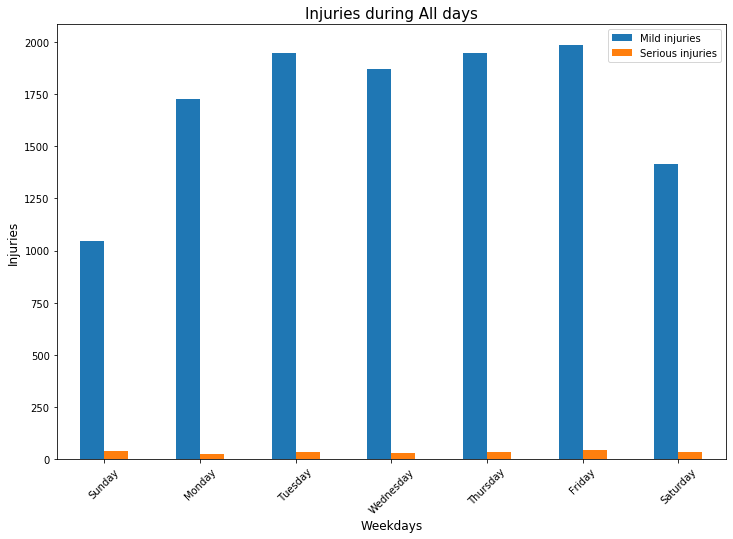

In [32]:
injuries_df=injuries_df.reset_index()
injuries_df.plot(y=['Mild injuries', 'Serious injuries'], x='Weekday', kind='bar', figsize=(12,8))
plt.xlabel('Weekdays',fontsize=12)
plt.xticks(rotation=45)
plt.ylabel('Injuries',fontsize=12)
plt.title("Injuries during All days",fontsize=15)
plt.show()

     Mild Injuries and Serious Injuries are not under one scale.Mild injuries are in 1000's and Serious injuries are below 100. Normalizing using Minmax Scaler to bring under one scale 


In [34]:
std=MinMaxScaler()
cols=['Mild injuries','Serious injuries']
injuries_df[cols]=std.fit_transform(injuries_df[cols].values)

injuries_df.head()

,Weekday,Mild injuries,Serious injuries,Day_id
0,Sunday,0.000000,0.705882,0
1,Monday,0.723586,0.000000,1
2,Tuesday,0.959445,0.411765,2
3,Wednesday,0.879402,0.235294,3
4,Thursday,0.959445,0.352941,4


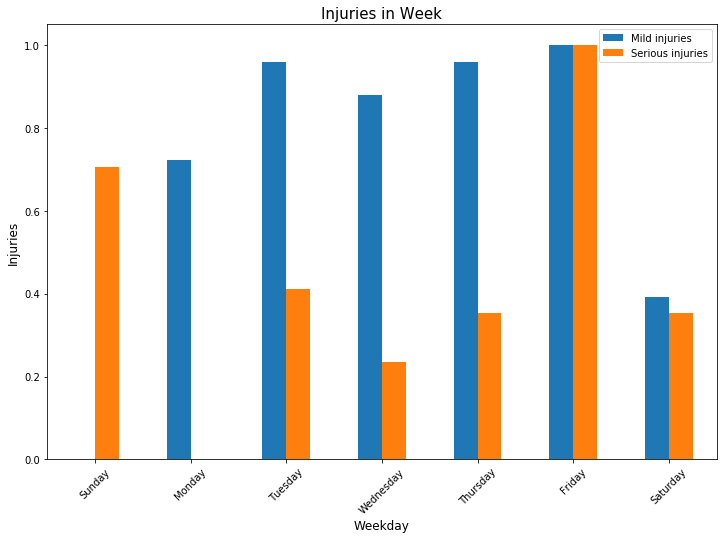

In [35]:
injuries_df.plot(y=['Mild injuries','Serious injuries'],x='Weekday',kind='bar',figsize=(12,8))
plt.xlabel('Weekday',fontsize=12)
plt.xticks(rotation=45)
plt.ylabel('Injuries',fontsize=12)
plt.title("Injuries in Week",fontsize=15)
plt.show()

In [36]:
barcelona.head()

,Id,District Name,Neighborhood Name,Street,Weekday,Month,Day,Hour,Part of the day,Mild injuries,Serious injuries,Victims,Vehicles involved,Longitude,Latitude
0,2017S008429,Baardheere,Unknown,Número 27 ...,Friday,October,13,8,morning,2,0,2,2,2.125624,41.340045
1,2017S007316,Baardheere,Unknown,Número 3 Zona Franca / Número 50 Zona Franca ...,Friday,September,1,13,afternoon,2,0,2,2,2.120452,41.339426
2,2017S010210,Baardheere,Unknown,Litoral (Besòs) ...,Friday,December,8,21,evening,5,0,5,2,2.167356,41.360885
3,2017S006364,Baardheere,Unknown,Número 3 Zona Franca ...,Friday,July,21,2,night,1,0,1,2,2.124529,41.337668
4,2017S004615,Sant Martí,el Camp de l'Arpa del Clot,Las Navas de Tolosa ...,Thursday,May,25,14,afternoon,1,0,1,3,2.185272,41.416365


In [50]:
#Part of day vs Injuries
timeofday = barcelona.groupby('Part of the day')['Mild injuries','Serious injuries'].sum()
print(timeofday.reset_index())

  Part of the day  Mild injuries  Serious injuries
0       afternoon           4722                68
1         evening           3242                83
2         morning           3151                63
3           night            818                27


In [51]:
timeofday_df = pd.DataFrame(timeofday)
sort = ['morning','afternoon','evening','night']
sortIndex = dict(zip(sort, range(len(sort))))
print(sortIndex)

{'morning': 0, 'afternoon': 1, 'evening': 2, 'night': 3}


In [52]:
timeofday_df['Time_id'] = timeofday_df.index
timeofday_df['Time_id'] = timeofday_df['Time_id'].map(sortIndex)
timeofday_df.head()

,Mild injuries,Serious injuries,Time_id
Part of the day,,,
afternoon,4722,68,1
evening,3242,83,2
morning,3151,63,0
night,818,27,3


In [53]:
timeofday_df.sort_values('Time_id',inplace=True)
timeofday_df.head()

,Mild injuries,Serious injuries,Time_id
Part of the day,,,
morning,3151,63,0
afternoon,4722,68,1
evening,3242,83,2
night,818,27,3


In [54]:
timeofday_df = timeofday_df.reset_index()
timeofday_df.head()

,Part of the day,Mild injuries,Serious injuries,Time_id
0,morning,3151,63,0
1,afternoon,4722,68,1
2,evening,3242,83,2
3,night,818,27,3


In [55]:
std1=MinMaxScaler()
cols1=['Mild injuries','Serious injuries']
timeofday_df[cols]=std1.fit_transform(timeofday_df[cols].values)

timeofday_df.head()

,Part of the day,Mild injuries,Serious injuries,Time_id
0,morning,0.597592,0.642857,0
1,afternoon,1.000000,0.732143,1
2,evening,0.620902,1.000000,2
3,night,0.000000,0.000000,3


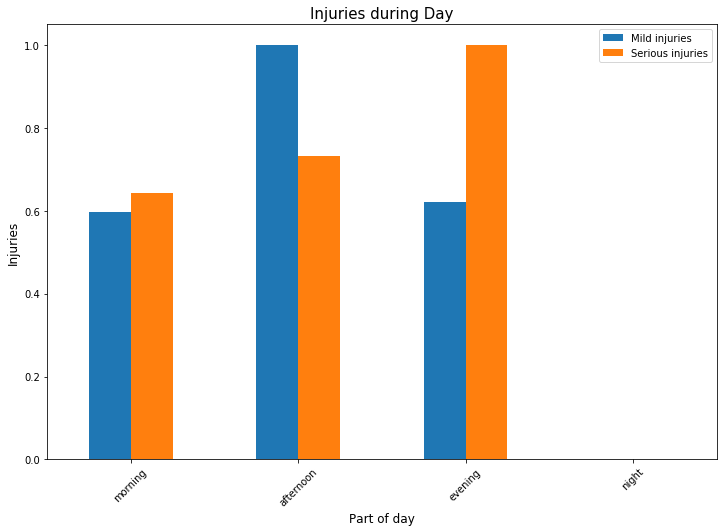

In [56]:
timeofday_df.plot(y=['Mild injuries','Serious injuries'],x='Part of the day',kind='bar',figsize=(12,8))
plt.xlabel('Part of day',fontsize=12)
plt.xticks(rotation=45)
plt.ylabel('Injuries',fontsize=12)
plt.title("Injuries during Day",fontsize=15)
plt.show()

In [57]:
victims = barcelona.groupby('Weekday')['Mild injuries','Serious injuries'].sum()

In [58]:
#Test of Independence
barcelona.head()


,Id,District Name,Neighborhood Name,Street,Weekday,Month,Day,Hour,Part of the day,Mild injuries,Serious injuries,Victims,Vehicles involved,Longitude,Latitude
0,2017S008429,Baardheere,Unknown,Número 27 ...,Friday,October,13,8,morning,2,0,2,2,2.125624,41.340045
1,2017S007316,Baardheere,Unknown,Número 3 Zona Franca / Número 50 Zona Franca ...,Friday,September,1,13,afternoon,2,0,2,2,2.120452,41.339426
2,2017S010210,Baardheere,Unknown,Litoral (Besòs) ...,Friday,December,8,21,evening,5,0,5,2,2.167356,41.360885
3,2017S006364,Baardheere,Unknown,Número 3 Zona Franca ...,Friday,July,21,2,night,1,0,1,2,2.124529,41.337668
4,2017S004615,Sant Martí,el Camp de l'Arpa del Clot,Las Navas de Tolosa ...,Thursday,May,25,14,afternoon,1,0,1,3,2.185272,41.416365


In [59]:
barcelona['Street'].value_counts()

Corts Catalanes                                       219
Diagonal                                              176
Litoral (Llobregat)                                   116
Litoral (Besòs)                                        99
Aragó                                                  95
                                                     ... 
Villarroel / Mallorca                                   1
FONERIA / Segura                                        1
Santa Madrona / Lleida                                  1
Montjuïc / Puig i Xoriguer                              1
Sicília / Casp                                          1
Name: Street, Length: 4253, dtype: int64

In [60]:
barcelona['District Name'].value_counts()

Eixample               3029
Sant Martí             1336
Sants-Montjuïc         1104
Sarrià-Sant Gervasi    1104
Horta-Guinardó          743
Les Corts               726
Ciutat Vella            600
Sant Andreu             597
Nou Barris              542
Gràcia                  531
Baardheere               27
Name: District Name, dtype: int64

In [61]:
catnames=['District Name','Weekday','Month','Part of the day','Mild injuries','Serious injuries','Victims','Vehicles involved']

    Since we have many categorical variables, we perform a chi2 test to identify independence between variables

In [62]:
factors_paired=[(i,j) for i in catnames for j in catnames]
chi2, p_values = [],[]
for f in factors_paired:
    if f[0]!=f[1]:
        chitest=chi2_contingency(pd.crosstab(barcelona[f[0]],barcelona[f[1]]))
        chi2.append(chitest[0])
        p_values.append(chitest[1])
    else:
        chi2.append(0)
        p_values.append(0)


p1=np.array(p_values).reshape((8,8))
#p1=np.array(p_values)
p1=pd.DataFrame(p1.round(2), index=catnames, columns=catnames)
p1


,District Name,Weekday,Month,Part of the day,Mild injuries,Serious injuries,Victims,Vehicles involved
District Name,0.00,0.07,0.00,0.00,0.0,0.19,0.0,0.0
Weekday,0.07,0.00,0.00,0.00,0.0,0.03,0.0,0.0
Month,0.00,0.00,0.00,0.20,0.0,0.13,0.0,0.4
Part of the day,0.00,0.00,0.20,0.00,0.0,0.01,0.0,0.0
Mild injuries,0.00,0.00,0.00,0.00,0.0,0.00,0.0,0.0
Serious injuries,0.19,0.03,0.13,0.01,0.0,0.00,0.0,0.0
Victims,0.00,0.00,0.00,0.00,0.0,0.00,0.0,0.0
Vehicles involved,0.00,0.00,0.40,0.00,0.0,0.00,0.0,0.0


In [63]:
# Null Hypothesis: Independant:(p value>0.05) # Accept Null Hypothesis 

# Alternate Hypothesis: Dependant:(p is <0.05) # Accept Alternate Hypothesis

In [64]:
p1.columns

Index(['District Name', 'Weekday', 'Month', 'Part of the day', 'Mild injuries',
       'Serious injuries', 'Victims', 'Vehicles involved'],
      dtype='object')

In [65]:
p1.index

Index(['District Name', 'Weekday', 'Month', 'Part of the day', 'Mild injuries',
       'Serious injuries', 'Victims', 'Vehicles involved'],
      dtype='object')

In [66]:
p2= p1[p1<0.05]
p2

,District Name,Weekday,Month,Part of the day,Mild injuries,Serious injuries,Victims,Vehicles involved
District Name,0.0,NaN,0.0,0.00,0.0,NaN,0.0,0.0
Weekday,NaN,0.00,0.0,0.00,0.0,0.03,0.0,0.0
Month,0.0,0.00,0.0,NaN,0.0,NaN,0.0,NaN
Part of the day,0.0,0.00,NaN,0.00,0.0,0.01,0.0,0.0
Mild injuries,0.0,0.00,0.0,0.00,0.0,0.00,0.0,0.0
Serious injuries,NaN,0.03,NaN,0.01,0.0,0.00,0.0,0.0
Victims,0.0,0.00,0.0,0.00,0.0,0.00,0.0,0.0
Vehicles involved,0.0,0.00,NaN,0.00,0.0,0.00,0.0,0.0


In [67]:
#Nan=Independant
#Dependant
for i in p2.index:
    for j in p2.columns:
        if ~np.isnan(p2.loc[i,j]) and i!=j:
            print((i,j))

('District Name', 'Month')
('District Name', 'Part of the day')
('District Name', 'Mild injuries')
('District Name', 'Victims')
('District Name', 'Vehicles involved')
('Weekday', 'Month')
('Weekday', 'Part of the day')
('Weekday', 'Mild injuries')
('Weekday', 'Serious injuries')
('Weekday', 'Victims')
('Weekday', 'Vehicles involved')
('Month', 'District Name')
('Month', 'Weekday')
('Month', 'Mild injuries')
('Month', 'Victims')
('Part of the day', 'District Name')
('Part of the day', 'Weekday')
('Part of the day', 'Mild injuries')
('Part of the day', 'Serious injuries')
('Part of the day', 'Victims')
('Part of the day', 'Vehicles involved')
('Mild injuries', 'District Name')
('Mild injuries', 'Weekday')
('Mild injuries', 'Month')
('Mild injuries', 'Part of the day')
('Mild injuries', 'Serious injuries')
('Mild injuries', 'Victims')
('Mild injuries', 'Vehicles involved')
('Serious injuries', 'Weekday')
('Serious injuries', 'Part of the day')
('Serious injuries', 'Mild injuries')
('Serio

In [68]:
barcelona.head()

,Id,District Name,Neighborhood Name,Street,Weekday,Month,Day,Hour,Part of the day,Mild injuries,Serious injuries,Victims,Vehicles involved,Longitude,Latitude
0,2017S008429,Baardheere,Unknown,Número 27 ...,Friday,October,13,8,morning,2,0,2,2,2.125624,41.340045
1,2017S007316,Baardheere,Unknown,Número 3 Zona Franca / Número 50 Zona Franca ...,Friday,September,1,13,afternoon,2,0,2,2,2.120452,41.339426
2,2017S010210,Baardheere,Unknown,Litoral (Besòs) ...,Friday,December,8,21,evening,5,0,5,2,2.167356,41.360885
3,2017S006364,Baardheere,Unknown,Número 3 Zona Franca ...,Friday,July,21,2,night,1,0,1,2,2.124529,41.337668
4,2017S004615,Sant Martí,el Camp de l'Arpa del Clot,Las Navas de Tolosa ...,Thursday,May,25,14,afternoon,1,0,1,3,2.185272,41.416365


### Model building

In [69]:
#Model Building
#Removing features not required for Model Building
Model4 = barcelona.drop(['Id','Neighborhood Name','Hour','Longitude','Latitude','Street','Victims',
                         'Vehicles involved','Day'],axis=1)

Model4.head()

,District Name,Weekday,Month,Part of the day,Mild injuries,Serious injuries
0,Baardheere,Friday,October,morning,2,0
1,Baardheere,Friday,September,afternoon,2,0
2,Baardheere,Friday,December,evening,5,0
3,Baardheere,Friday,July,night,1,0
4,Sant Martí,Thursday,May,afternoon,1,0


In [70]:
Model4['Mild injuries'].value_counts()

1     7253
2     1579
0     1082
3      273
4       99
5       31
6       11
7        7
10       2
9        1
8        1
Name: Mild injuries, dtype: int64

In [71]:
Model4['Serious injuries'].value_counts()

0    10116
1      207
2       15
4        1
Name: Serious injuries, dtype: int64

In [73]:
le = LabelEncoder()
Model4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10339 entries, 0 to 10338
Data columns (total 6 columns):
District Name       10339 non-null object
Weekday             10339 non-null object
Month               10339 non-null object
Part of the day     10339 non-null object
Mild injuries       10339 non-null int64
Serious injuries    10339 non-null int64
dtypes: int64(2), object(4)
memory usage: 484.8+ KB


In [74]:
#Transforming Categorical to Numeric
for col in Model4.select_dtypes('object'):
    Model4[col] = le.fit_transform(Model4[col] )
Model4.head()

,District Name,Weekday,Month,Part of the day,Mild injuries,Serious injuries
0,0,0,10,2,2,0
1,0,0,11,0,2,0
2,0,0,2,1,5,0
3,0,0,5,3,1,0
4,8,4,8,0,1,0


In [75]:
Model4['Part of the day'].value_counts()

0    4030
2    2816
1    2748
3     745
Name: Part of the day, dtype: int64

In [153]:
x=Model4.drop(['Serious injuries'],axis=1)
Y=Model4['Serious injuries']
Y = Y.astype('category')
x_train,x_test,Y2_train,Y2_test=train_test_split(x,Y,train_size=0.7,test_size=0.3,random_state=123)

In [154]:
x_train.head()

,District Name,Weekday,Month,Part of the day,Mild injuries
450,2,3,11,3,0
5295,1,0,8,0,0
2448,7,0,9,0,2
4026,1,6,7,1,1
4076,2,4,0,2,1


In [155]:
logreg2 = LogisticRegression(multi_class='ovr')
logreg2.fit(x_train,Y2_train)

Y2_pred=logreg2.predict(x_test)


In [156]:
acc_log = round(logreg2.score(x_train, Y2_train)*100, 2)
print(round(acc_log,2,),"%")

97.68 %


In [157]:
acc = accuracy_score(Y2_pred, Y2_test)
acc

0.9822695035460993

In [158]:
cnf_matrix = confusion_matrix(Y2_test, Y2_pred)
cnf_matrix


array([[3047,    0,    0],
       [  52,    0,    0],
       [   3,    0,    0]], dtype=int64)

In [159]:
print(classification_report(Y2_test, Y2_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3047
           1       0.00      0.00      0.00        52
           2       0.00      0.00      0.00         3

    accuracy                           0.98      3102
   macro avg       0.33      0.33      0.33      3102
weighted avg       0.96      0.98      0.97      3102



C:\Users\manik\Anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1272: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Text(0.5, 257.44, 'Predicted label')

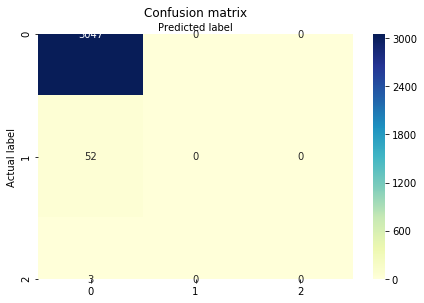

In [130]:
%matplotlib inline
class_names=[0,1] # name of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
# create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

In [160]:
print("Accuracy:",metrics.accuracy_score(Y2_test, Y2_pred))
print("Precision:",metrics.precision_score(Y2_test, Y2_pred,pos_label='positive',average='micro'))
print("Recall:",metrics.recall_score(Y2_test, Y2_pred,pos_label='positive',average='micro'))

Accuracy: 0.9822695035460993
Precision: 0.9822695035460993
Recall: 0.9822695035460993


C:\Users\manik\Anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1321: UserWarning: Note that pos_label (set to 'positive') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  % (pos_label, average), UserWarning)


In [167]:
X = Model4.drop(['Serious injuries'],axis=1)
y = Model4['Serious injuries']
y = Y.astype('category')
y = label_binarize(Y,classes=[0,1,2,3])
X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.7,test_size=0.3,random_state=123)

In [171]:
RandomForestRegressor().get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'mse',
 'max_depth': None,
 'max_features': 'auto',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_impurity_split': None,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [177]:
param_grid = {'n_estimators':[50,100,200,400,600,80,20]}
grid = GridSearchCV(RandomForestClassifier(n_jobs=-1),cv=3,param_grid=param_grid,scoring='f1_samples')
grid.fit(X_train,y_train)
y_pred = grid.best_estimator_.predict(X_test)

In [179]:
metrics.f1_score(y_pred,y_test,average='samples')

0.9758220502901354

In [182]:
print(metrics.classification_report(y_pred,y_test))

              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3076
           1       0.06      0.16      0.08        19
           2       0.00      0.00      0.00         2
           3       0.00      0.00      0.00         0

   micro avg       0.98      0.98      0.98      3097
   macro avg       0.26      0.29      0.27      3097
weighted avg       0.99      0.98      0.98      3097
 samples avg       0.98      0.98      0.98      3097



    This is a very good score considering the huge imbalance in the classes. Though our logistic regression model did pretty bad considering it only predicted 0 for all available classes. We have used a "onevsrestclassifier" to deal with the multi-class classification